In [ ]:
# ==========================================
# STEP 1: MOUNT GOOGLE DRIVE
# ==========================================

from google.colab import drive
drive.mount('/content/drive')

print("Google Drive connected successfully!")

Mounted at /content/drive
Google Drive connected successfully!


In [ ]:
# ==========================================
# STEP 2: SET DATASET PATHS
# ==========================================

import os

drive_path = "/content/drive/MyDrive/Smart_Campus_Scene_Recognition"

base_path = os.path.join(drive_path, "archive (1)")

train_dir = os.path.join(base_path, "train", "train")
test_dir = os.path.join(base_path, "test", "test")

print("Dataset folder:", base_path)
print("Training folder exists:", os.path.isdir(train_dir))
print("Testing folder exists:", os.path.isdir(test_dir))

if not os.path.isdir(train_dir) or not os.path.isdir(test_dir):
    raise FileNotFoundError(
        "Dataset folders not found. Check the Google Drive path."
    )

print("Training categories:", len(os.listdir(train_dir)))
print("Testing categories:", len(os.listdir(test_dir)))

Dataset folder: /content/drive/MyDrive/Smart_Campus_Scene_Recognition/archive (1)
Training folder exists: True
Testing folder exists: True
Training categories: 67
Testing categories: 67


In [ ]:
# ==========================================
# STEP 3: DEFINE SIX PROJECT CLASSES
# ==========================================

category_mapping = {
    "Classroom": ["classroom"],
    "Common_Canteen": [
        "buffet",
        "fastfood_restaurant",
        "restaurant"
    ],
    "Corridor": ["corridor"],
    "Laboratory": ["laboratorywet"],
    "Library": ["library"],
    "Office": ["office"]
}

print("Project classes:")

for project_class, source_classes in category_mapping.items():
    print(f"{project_class}: {source_classes}")

Project classes:
Classroom: ['classroom']
Common_Canteen: ['buffet', 'fastfood_restaurant', 'restaurant']
Corridor: ['corridor']
Laboratory: ['laboratorywet']
Library: ['library']
Office: ['office']


In [ ]:
# ==========================================
# STEP 4: CHECK SOURCE IMAGE COUNTS
# ==========================================

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def count_images_recursive(folder):
    if not os.path.isdir(folder):
        return 0

    return sum(
        1
        for root, dirs, files in os.walk(folder)
        for filename in files
        if filename.lower().endswith(valid_extensions)
    )

print("SIX-CLASS DATASET SUMMARY")
print("-" * 55)

total_train = 0
total_test = 0

for project_class, source_classes in category_mapping.items():
    train_count = sum(
        count_images_recursive(os.path.join(train_dir, c))
        for c in source_classes
    )

    test_count = sum(
        count_images_recursive(os.path.join(test_dir, c))
        for c in source_classes
    )

    total_train += train_count
    total_test += test_count

    print(
        f"{project_class:18s} "
        f"Train: {train_count:3d} | Test: {test_count:3d}"
    )

print("-" * 55)
print("Total training images:", total_train)
print("Total testing images:", total_test)

SIX-CLASS DATASET SUMMARY
-------------------------------------------------------
Classroom          Train:  80 | Test:  20
Common_Canteen     Train: 240 | Test:  60
Corridor           Train:  80 | Test:  20
Laboratory         Train:  80 | Test:  20
Library            Train:  80 | Test:  20
Office             Train:  80 | Test:  20
-------------------------------------------------------
Total training images: 640
Total testing images: 160


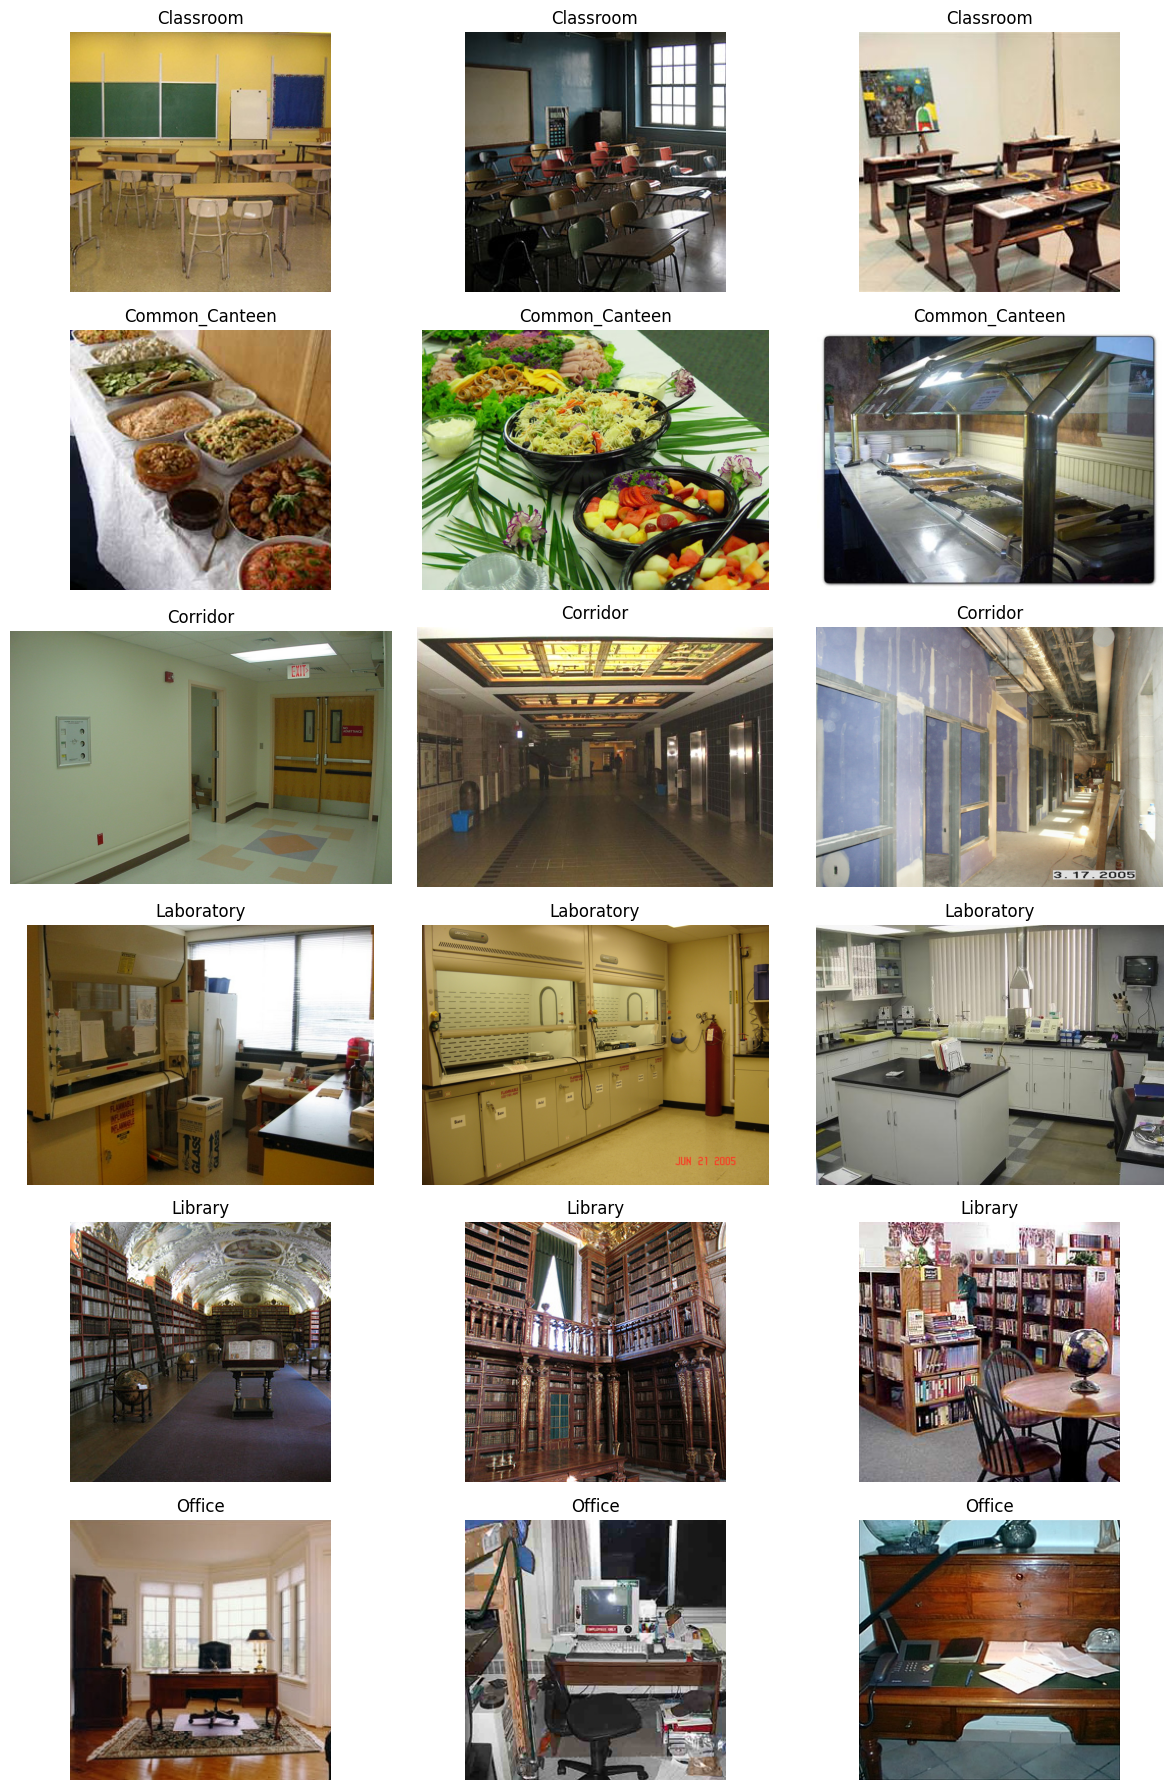

In [ ]:
# ==========================================
# STEP 5: VISUALIZE SAMPLE TRAINING IMAGES
# ==========================================

import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

fig, axes = plt.subplots(6, 3, figsize=(12, 18))

for row, (project_class, source_classes) in enumerate(
    category_mapping.items()
):
    image_paths = []

    for source_class in source_classes:
        folder = os.path.join(train_dir, source_class)

        for root, dirs, files in os.walk(folder):
            for filename in files:
                if filename.lower().endswith(valid_extensions):
                    image_paths.append(os.path.join(root, filename))

    selected = random.sample(image_paths, min(3, len(image_paths)))

    for col in range(3):
        axes[row, col].axis("off")

        if col < len(selected):
            with Image.open(selected[col]) as img:
                axes[row, col].imshow(img.convert("RGB"))

            axes[row, col].set_title(project_class)

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# STEP 6: PREPARE THE SIX-CLASS DATASET
# ==========================================

import shutil

prepared_dir = "/content/campus_dataset"

# Rebuild the destination to prevent duplicate/stale images
if os.path.exists(prepared_dir):
    shutil.rmtree(prepared_dir)

train_prepared = os.path.join(prepared_dir, "train")
test_prepared = os.path.join(prepared_dir, "test")

for split_dir in [train_prepared, test_prepared]:
    for project_class in category_mapping:
        os.makedirs(
            os.path.join(split_dir, project_class),
            exist_ok=True
        )

for split_name, source_root, destination_root in [
    ("train", train_dir, train_prepared),
    ("test", test_dir, test_prepared)
]:
    for project_class, source_classes in category_mapping.items():
        destination_folder = os.path.join(
            destination_root, project_class
        )

        for source_class in source_classes:
            source_folder = os.path.join(source_root, source_class)

            if not os.path.isdir(source_folder):
                raise FileNotFoundError(
                    f"Missing source category: {source_folder}"
                )

            for root, dirs, filenames in os.walk(source_folder):
                for filename in filenames:
                    if filename.lower().endswith(valid_extensions):
                        source_file = os.path.join(root, filename)

                        # Include the original category in the filename
                        destination_file = os.path.join(
                            destination_folder,
                            f"{source_class}_{filename}"
                        )

                        shutil.copy2(source_file, destination_file)

print("Six-class dataset prepared!")

for split_name, split_folder in [
    ("TRAIN", train_prepared),
    ("TEST", test_prepared)
]:
    print(f"\n{split_name}")

    for project_class in category_mapping:
        folder = os.path.join(split_folder, project_class)
        print(project_class, ":", count_images_recursive(folder))

Six-class dataset prepared!

TRAIN
Classroom : 80
Common_Canteen : 240
Corridor : 80
Laboratory : 80
Library : 80
Office : 80

TEST
Classroom : 20
Common_Canteen : 60
Corridor : 20
Laboratory : 20
Library : 20
Office : 20


In [ ]:
# ==========================================
# STEP 7: CHECK GPU AND IMPORT PYTORCH
# ==========================================

import torch
import torchvision
import numpy as np

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
GPU available: False


In [ ]:
# ==========================================
# STEP 8: PREPROCESS AND LOAD DATASETS
# ==========================================

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Training transformations include horizontal flipping
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Test transformations must be deterministic
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    train_prepared,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_prepared,
    transform=test_transform
)

# Use a seeded generator for repeatable shuffle order
generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=generator,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Classes:", train_dataset.classes)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Number of classes:", len(train_dataset.classes))

Classes: ['Classroom', 'Common_Canteen', 'Corridor', 'Laboratory', 'Library', 'Office']
Training images: 640
Testing images: 160
Number of classes: 6


In [ ]:
# ==========================================
# STEP 9: BUILD THE MOBILENETV3 MODEL
# ==========================================

import torch.nn as nn
from torchvision import models

weights = models.MobileNet_V3_Large_Weights.DEFAULT

model = models.mobilenet_v3_large(weights=weights)

# Freeze the pretrained feature extraction layers
for parameter in model.features.parameters():
    parameter.requires_grad = False

# Replace the final layer with six output classes
num_features = model.classifier[3].in_features

model.classifier[3] = nn.Linear(
    num_features,
    len(train_dataset.classes)
)

model = model.to(device)

print("Model: MobileNetV3-Large")
print("Device:", device)
print("Classes:", train_dataset.classes)
print("Model ready for training!")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 131MB/s]


Model: MobileNetV3-Large
Device: cpu
Classes: ['Classroom', 'Common_Canteen', 'Corridor', 'Laboratory', 'Library', 'Office']
Model ready for training!


In [ ]:
# ==========================================
# STEP 10: TRAIN THE MODEL
# ==========================================

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

num_epochs = 5

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backpropagation and parameter update
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Training Accuracy: {epoch_accuracy:.2f}%"
    )

print("Training completed!")

Epoch [1/5] Loss: 1.2160 Training Accuracy: 57.34%
Epoch [2/5] Loss: 0.4735 Training Accuracy: 85.94%
Epoch [3/5] Loss: 0.2228 Training Accuracy: 94.06%
Epoch [4/5] Loss: 0.1488 Training Accuracy: 96.56%
Epoch [5/5] Loss: 0.1276 Training Accuracy: 96.88%
Training completed!


Top-1 Test Accuracy: 86.25%
Top-3 Test Accuracy: 98.12%
Macro-F1 Score: 0.8663

Classification Report:
                precision    recall  f1-score   support

     Classroom       0.82      0.90      0.86        20
Common_Canteen       1.00      0.77      0.87        60
      Corridor       1.00      0.95      0.97        20
    Laboratory       0.82      0.90      0.86        20
       Library       0.62      1.00      0.77        20
        Office       0.89      0.85      0.87        20

      accuracy                           0.86       160
     macro avg       0.86      0.89      0.87       160
  weighted avg       0.89      0.86      0.87       160



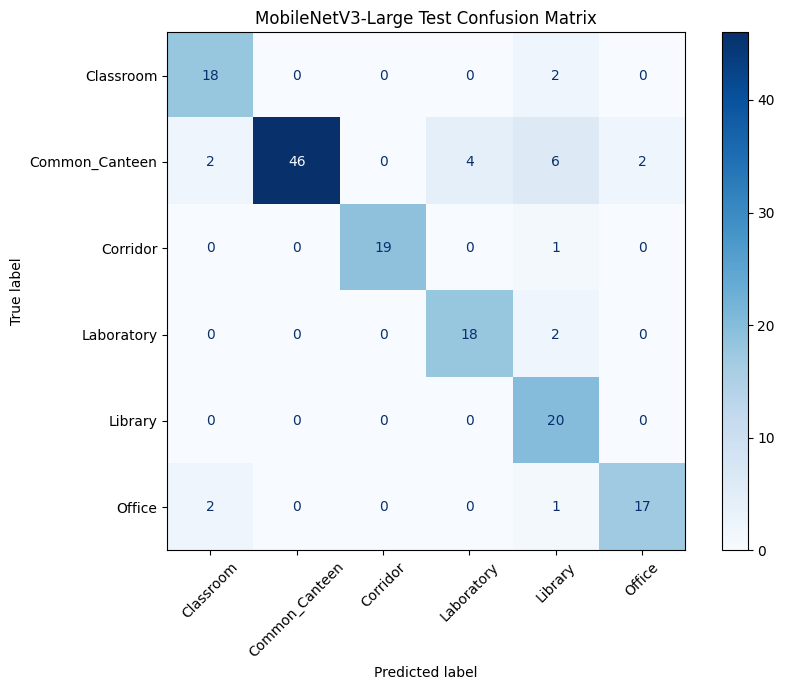

In [ ]:
# ==========================================
# STEP 11: EVALUATE THE TRAINED MODEL
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Top-1 accuracy and Macro-F1
test_accuracy = accuracy_score(all_labels, all_predictions)

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

# Top-3 accuracy
all_probabilities = np.array(all_probabilities)
all_labels_array = np.array(all_labels)

top3_indices = np.argsort(
    all_probabilities, axis=1
)[:, -3:]

top3_correct = sum(
    label in predictions
    for label, predictions in zip(all_labels_array, top3_indices)
)

top3_accuracy = top3_correct / len(all_labels_array)

print(f"Top-1 Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Top-3 Test Accuracy: {top3_accuracy * 100:.2f}%")
print(f"Macro-F1 Score: {macro_f1:.4f}")
print("\nClassification Report:")

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(test_dataset.classes))),
    target_names=test_dataset.classes,
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(test_dataset.classes)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
)

fig, ax = plt.subplots(figsize=(9, 7))
display.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("MobileNetV3-Large Test Confusion Matrix")
plt.tight_layout()
plt.show()

Saving corridoor.jpeg to corridoor (1).jpeg


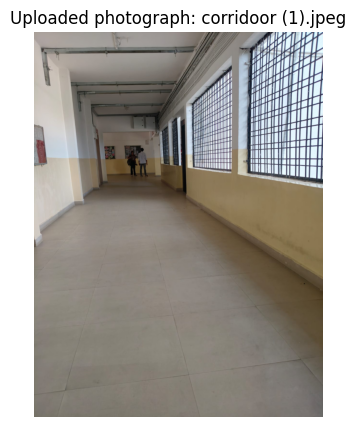

Predicted scene: Corridor

Top-three predictions:
Corridor: 98.64%
Laboratory: 0.77%
Library: 0.35%


In [ ]:
# ==========================================
# STEP 12: PREDICT A CAMPUS PHOTOGRAPH
# ==========================================

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded.")

image_name = next(iter(uploaded))

# Keep the original image for display
original_image = Image.open(image_name).convert("RGB")

# Prepare the image using the same preprocessing as testing
input_tensor = test_transform(original_image).unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0]

top_probs, top_indices = torch.topk(probabilities, k=3)

# Display the actual uploaded photograph
plt.figure(figsize=(7, 5))
plt.imshow(original_image)
plt.title(f"Uploaded photograph: {image_name}")
plt.axis("off")
plt.show()

# Display the prediction results
print("Predicted scene:", train_dataset.classes[top_indices[0].item()])
print("\nTop-three predictions:")

for probability, index in zip(top_probs, top_indices):
    print(
        f"{train_dataset.classes[index.item()]}: "
        f"{probability.item() * 100:.2f}%"
    )

In [ ]:
# ==========================================
# STEP 13: MEASURE MODEL INFERENCE SPEED
# ==========================================

import time

# Use one test image
sample_image, sample_label = test_dataset[0]
sample_input = sample_image.unsqueeze(0).to(device)

# Warm up the model
model.eval()

with torch.no_grad():
    for _ in range(10):
        _ = model(sample_input)

if device.type == "cuda":
    torch.cuda.synchronize()

# Measure repeated inference
num_runs = 100

start_time = time.perf_counter()

with torch.no_grad():
    for _ in range(num_runs):
        _ = model(sample_input)

if device.type == "cuda":
    torch.cuda.synchronize()

total_time = time.perf_counter() - start_time

average_time_ms = (total_time / num_runs) * 1000
fps = num_runs / total_time

print(f"Device: {device}")
print(f"Average inference time: {average_time_ms:.2f} ms/image")
print(f"Approximate inference throughput: {fps:.2f} images/second")

Device: cpu
Average inference time: 30.30 ms/image
Approximate inference throughput: 33.00 images/second


In [ ]:
# ==========================================
# STEP 14: SAVE MODEL AND METRICS
# ==========================================

output_dir = os.path.join(drive_path, "model_output")
os.makedirs(output_dir, exist_ok=True)

model_path = os.path.join(
    output_dir, "mobilenetv3_six_class.pth"
)

# Save model weights and relevant metadata
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": train_dataset.classes,
    "test_accuracy": float(test_accuracy),
    "macro_f1": float(macro_f1),
    "top3_accuracy": float(top3_accuracy),
    "num_epochs": num_epochs,
    "architecture": "MobileNetV3-Large"
}, model_path)

# Save evaluation results as a text file
report_path = os.path.join(output_dir, "evaluation_results.txt")

with open(report_path, "w") as f:
    f.write("Smart Campus Scene Recognition\n")
    f.write("Model: MobileNetV3-Large\n")
    f.write(f"Training images: {len(train_dataset)}\n")
    f.write(f"Testing images: {len(test_dataset)}\n")
    f.write(f"Top-1 Test Accuracy: {test_accuracy * 100:.2f}%\n")
    f.write(f"Top-3 Test Accuracy: {top3_accuracy * 100:.2f}%\n")
    f.write(f"Macro-F1: {macro_f1:.4f}\n")
    f.write(f"Average inference time: {average_time_ms:.2f} ms\n")
    f.write(f"Approximate throughput: {fps:.2f} images/second\n")
    f.write(f"Class names: {train_dataset.classes}\n")

print("Model saved:", model_path)
print("Evaluation report saved:", report_path)

Model saved: /content/drive/MyDrive/Smart_Campus_Scene_Recognition/model_output/mobilenetv3_six_class.pth
Evaluation report saved: /content/drive/MyDrive/Smart_Campus_Scene_Recognition/model_output/evaluation_results.txt
